# Artificial Intelligence


* Md. Jalil Piran
* Sejong University
* piran@sejong.ac.kr


# Artificial Neural Network
## Used Car Price Prediction and Comparison with Linear Regression


### Lesson overview

- **Goal:** predict the advertised price of a used Ford car using the same eight predictors and cleaning rules as the supplied Linear Regression notebook.
- **Main comparison:** Artificial Neural Network (ANN) versus ordinary Linear Regression (LR). A training-median baseline is also included. The source notebook's log-target Linear Regression is retained as an optional additional reference.
- **Teaching format:** a numbered explanation before every code cell, followed by guidance on interpreting its result.
- **Required data:** put the original `ford.csv` beside this notebook, or change `DATA_PATH`. The CSV is not embedded in the supplied notebook. Historical outputs cannot reconstruct the full dataset.
- **Data status:** this notebook contains no precomputed Ford experiment results. Its code was checked with a separate synthetic fixture; those synthetic scores are not included. Run all cells with your original CSV to obtain the actual comparison.
- **Environment:** Python 3.10 or newer; NumPy, pandas, Matplotlib, seaborn, SciPy, scikit-learn 1.2 or newer, IPython, and threadpoolctl. The code was checked with scikit-learn 1.8.0.
- **Setup if needed:** run `%pip install numpy pandas matplotlib seaborn scipy "scikit-learn>=1.2" ipython threadpoolctl` in a separate setup cell, then restart the kernel.
- **Run order:** execute from top to bottom in Jupyter, VS Code, or Colab. In Colab, upload the CSV or mount your own Drive before setting its path. No TensorFlow installation or GPU is needed.
- **Units:** use the source CSV's currency and measurement units. Confirm the dataset documentation before labeling price as pounds or mileage as miles.

**Learning objectives**

1. Prepare mixed numeric and categorical data without learning from evaluation rows.
2. Explain a neuron, hidden layer, activation function, forward pass, loss, backpropagation, batch, and epoch.
3. Train a feed-forward ANN with target scaling and validation-based early stopping.
4. Compare LR and ANN using identical held-out records, shared cross-validation folds, several metrics, and residual diagnostics.
5. Distinguish a measured improvement on this dataset from a general claim that one model is always better.

**Road map:** Sections 1–13 reproduce the source's data workflow; 14–21 introduce the ANN and fair evaluation; 22–24 train and inspect the networks; 25–31 compare results; 32–33 predict a new car and optionally export the results.


### 1. Import the libraries

- Keep the scientific Python tools used in the LR lesson.
- `MLPRegressor` implements a multilayer perceptron: a fully connected feed-forward ANN for regression.
- `clone` creates independent, unfitted copies of preprocessing and reference models.
- `threadpool_limits` uses one numerical-library thread during fitting so small networks do not suffer excessive thread overhead. Timing results remain machine dependent.


In [2]:
from pathlib import Path
from time import perf_counter
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import seaborn as sns
from scipy import stats
from IPython.display import display
from threadpoolctl import threadpool_limits

import sklearn
from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    median_absolute_error, mean_absolute_percentage_error
)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4), "figure.dpi": 110})
COLORS = {"Linear Regression": "#3676B3", "ANN": "#D66B35",
          "Log-target Linear Regression": "#47917B", "Median baseline": "#8B8F98"}
print("Python:", platform.python_version())
print("scikit-learn:", sklearn.__version__)

Python: 3.12.4
scikit-learn: 1.4.2


**Read the result**

Keep the printed versions with your results. A fixed seed improves repeatability, but different library versions or hardware can still produce small numerical differences.


### 2. Configure paths, reproducibility, and the ANN

- Preserve the original **70% training / 30% test split**, random seed 42, and five cross-validation folds.
- Within each training pool, reserve 20% temporarily for ANN epoch selection. The final ANN is then refitted on the entire training pool for the selected number of epochs.
- For the final fit, the temporary proportions are approximately 56% fitting / 14% validation / 30% test; after epoch selection, both final models use the same full 70% training pool.
- Fix the architecture and settings before inspecting the test set. **RMSE is the primary comparison metric**, with MAE and the remaining metrics providing complementary interpretation.
- Keep the source's domain rules. Engine size zero is treated as missing unless the dataset documentation establishes another meaning.
- Leave optional CSV export disabled until you want files written on your own computer.


In [3]:
DATA_PATH = Path("ford.csv")
RANDOM_STATE = 42
TEST_SIZE = 0.30
CV_FOLDS = 5
MIN_MODEL_YEAR = 1900
MAX_MODEL_YEAR = pd.Timestamp.today().year + 1
ZERO_ENGINE_SIZE_IS_MISSING = True

ANN_HIDDEN_LAYERS = (64, 32)
ANN_LEARNING_RATE = 0.001
ANN_ALPHA = 0.0001
ANN_BATCH_SIZE = 128
ANN_MAX_EPOCHS = 400
ANN_PATIENCE = 25
ANN_MIN_DELTA = 1e-4       # Required improvement in standardized validation RMSE.
ANN_VALIDATION_SIZE = 0.20

RUN_LOG_LR_REFERENCE = True
RUN_BOOTSTRAP = True
BOOTSTRAP_REPEATS = 2000
SAVE_RESULTS = False
OUTPUT_DIR = Path("ann_lr_results")

numeric_features = ["year", "mileage", "tax", "mpg", "engineSize"]
categorical_features = ["model", "transmission", "fuelType"]
feature_columns = numeric_features + categorical_features
target_column = "price"
required_columns = feature_columns + [target_column]

if not (0 < TEST_SIZE < 1 and 0 < ANN_VALIDATION_SIZE < 1):
    raise ValueError("Split fractions must be between 0 and 1.")
if CV_FOLDS < 2 or ANN_MAX_EPOCHS < 1 or ANN_PATIENCE < 1:
    raise ValueError("Use at least two CV folds and positive epoch/patience limits.")
print("ANN hidden layers:", ANN_HIDDEN_LAYERS)
print("Primary metric: RMSE in source currency units.")


ANN hidden layers: (64, 32)
Primary metric: RMSE in source currency units.


**Read the result**

The defaults describe one reasonable teaching experiment, not an optimized architecture. ANN cross-validation is slower than fitting LR because it includes validation-based epoch selection and a fresh refit in every fold.


### 3. Load and preview the source data

- Read the full CSV without changing the working directory and retain `raw_df` unchanged.
- Stop with a clear message if the real dataset is missing; no synthetic fallback is silently substituted.
- Treat any historical row counts or scores in the original notebook as historical outputs, not required answers for a new file.


In [4]:
data_path = Path(DATA_PATH).expanduser()
if not data_path.is_file():
    raise FileNotFoundError(
        f"Cannot find {data_path.resolve()}. Put the original ford.csv beside "
        "this notebook or set DATA_PATH to its location. The uploaded LR "
        "notebook contains saved outputs, not the full source dataset."
    )
raw_df = pd.read_csv(data_path)
print(f"Loaded {len(raw_df):,} rows and {raw_df.shape[1]} columns.")
display(raw_df.head())


Loaded 17,965 rows and 9 columns.


,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.7,1.0
1,Focus,2018,14000,Manual,9083,Petrol,150,57.7,1.0
2,Focus,2017,13000,Manual,12456,Petrol,150,57.7,1.0
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.3,1.5
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.7,1.0


**Read the result**

There should be eight predictor columns plus `price`. The category labels are text, and the target is a continuous numeric price, so this is a regression problem.


### 4. Inspect column types and missing values

- Check the original data types, nonmissing counts, and column names.
- Display missing counts rather than assuming that the new CSV matches the original saved output.
- Keep this inspection separate from model fitting.


In [5]:
raw_df.info()
display(raw_df.isna().sum().to_frame("Original missing values"))
print("Original columns:", raw_df.columns.tolist())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17965 entries, 0 to 17964
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         17965 non-null  object 
 1   year          17965 non-null  int64  
 2   price         17965 non-null  int64  
 3   transmission  17965 non-null  object 
 4   mileage       17965 non-null  int64  
 5   fuelType      17965 non-null  object 
 6   tax           17965 non-null  int64  
 7   mpg           17965 non-null  float64
 8   engineSize    17965 non-null  float64
dtypes: float64(2), int64(4), object(3)
memory usage: 1.2+ MB


,Original missing values
model,0
year,0
price,0
transmission,0
mileage,0
fuelType,0
tax,0
mpg,0
engineSize,0


Original columns: ['model', 'year', 'price', 'transmission', 'mileage', 'fuelType', 'tax', 'mpg', 'engineSize']


**Read the result**

Missing values and inconsistent types need attention before modeling. A column with an integer dtype is not automatically an appropriate numerical predictor: meaning matters.


### 5. Validate the schema and normalize text

- Remove whitespace from column names and category labels, including the leading spaces commonly present in car model names.
- Keep model, transmission, and fuel type as nominal categories instead of replacing them with arbitrary integers.
- Represent blank categories as missing values and convert numeric columns explicitly; report nonnumeric entries rather than silently accepting them.


In [6]:
df = raw_df.copy()
df.index.name = "source_row"
df.columns = df.columns.str.strip()
if df.columns.duplicated().any():
    raise ValueError("Duplicate column names after whitespace normalization.")
missing_columns = set(required_columns).difference(df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")
df = df[required_columns].copy()

for column in categorical_features:
    df[column] = df[column].map(lambda value: value.strip() if isinstance(value, str) else value)
    df[column] = df[column].replace(r"^\s*$", np.nan, regex=True)

invalid_numeric = {}
for column in numeric_features + [target_column]:
    parsed = pd.to_numeric(df[column], errors="coerce")
    invalid_numeric[column] = int((df[column].notna() & parsed.isna()).sum())
    df[column] = parsed.replace([np.inf, -np.inf], np.nan).astype(float)
display(pd.Series(invalid_numeric, name="Nonnumeric values converted to missing").to_frame())


,Nonnumeric values converted to missing
year,0
mileage,0
tax,0
mpg,0
engineSize,0
price,0


**Read the result**

A conversion count above zero means the source contained an entry that was not interpretable as a number. Blank categories become missing values; the most frequent category is learned later from fitting rows only.


### 6. Handle invalid values and repeated records

- Remove rows with missing or nonpositive prices because a missing target must not be imputed.
- Convert implausible years, negative mileage or tax, nonpositive mpg, and invalid engine sizes to missing; learn imputation values later from training data only.
- Keep an audit table with the number of affected values; do not replace 2060 with an invented year.
- Remove exact repeated records before splitting to reduce duplicate leakage; identical specifications can also represent different real cars, so review this policy if unique listing identifiers become available.
- Retain unusual but valid prices and mileage values rather than deleting outliers using test-set statistics.


In [7]:
audit = []
bad_target = df[target_column].isna() | df[target_column].le(0)
audit.append({"Action": "Remove missing/nonpositive target", "Count": int(bad_target.sum())})
df = df.loc[~bad_target].copy()

invalid_masks = {
    "year": df["year"].notna() & (
        ~df["year"].between(MIN_MODEL_YEAR, MAX_MODEL_YEAR)
        | df["year"].mod(1).ne(0)
    ),
    "mileage": df["mileage"].lt(0),
    "tax": df["tax"].lt(0),
    "mpg": df["mpg"].le(0),
    "engineSize": df["engineSize"].le(0) if ZERO_ENGINE_SIZE_IS_MISSING else df["engineSize"].lt(0)
}
for column, mask in invalid_masks.items():
    audit.append({"Action": f"Set invalid {column} to missing", "Count": int(mask.sum())})
    df.loc[mask, column] = np.nan

duplicate_count = int(df.duplicated().sum())
audit.append({"Action": "Remove exact duplicate records", "Count": duplicate_count})
df = df.drop_duplicates().copy()
if len(df) < 30:
    raise ValueError("Use at least 30 valid, distinct observations for this holdout/CV workflow.")
all_missing = [column for column in feature_columns if df[column].isna().all()]
if all_missing:
    raise ValueError(f"Features contain no observed values: {all_missing}")
if df[target_column].nunique() < 2:
    raise ValueError("Price must vary to fit and evaluate this regression example.")
display(pd.DataFrame(audit))
print(f"Retained {len(df):,} records.")
display(df.isna().sum().to_frame("Missing after validation"))


,Action,Count
0,Remove missing/nonpositive target,0
1,Set invalid year to missing,1
2,Set invalid mileage to missing,0
3,Set invalid tax to missing,0
4,Set invalid mpg to missing,0
5,Set invalid engineSize to missing,51
6,Remove exact duplicate records,154


Retained 17,811 records.


,Missing after validation
year,1
mileage,0
tax,0
mpg,0
engineSize,51
model,0
transmission,0
fuelType,0
price,0


**Read the result**

The audit reports what was removed or marked missing. Missing predictors will be imputed within each fitting subset. Missing targets are removed because their correct prices are unknown. The remaining index is the original zero-based CSV data-row index.


### 7. Define predictors and hold out test records

- Use all eight available predictors, including the car model, and keep named DataFrame columns throughout.
- Split before exploratory analysis so the following plots and cross-validation use training data only.
- A reproducible random split estimates performance for similar listings from the same population; it does not establish future-market performance or prevent the same physical car appearing in different nonidentical listings.
- Use time- or vehicle-group-based splits instead if listing dates or vehicle identifiers are later available.


In [8]:
X = df[feature_columns].copy()
y = df[target_column].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
if y_train.nunique() < 2:
    raise ValueError("Training prices must vary.")
all_missing_train = [column for column in feature_columns if X_train[column].isna().all()]
if all_missing_train:
    raise ValueError(f"No observed training values for: {all_missing_train}")
if len(X_train) < 2 * CV_FOLDS:
    raise ValueError("Too few training rows for the requested CV folds.")
if y_test.nunique() < 2:
    print("Caution: test R² will be undefined because test prices do not vary.")
assert X_train.index.intersection(X_test.index).empty
train_df = X_train.assign(price=y_train)
print("X / y:", X.shape, y.shape)
print("Training X / y:", X_train.shape, y_train.shape)
print("Test X / y:", X_test.shape, y_test.shape)


X / y: (17811, 8) (17811,)
Training X / y: (12467, 8) (12467,)
Test X / y: (5344, 8) (5344,)


**Read the result**

The test rows are now reserved. Training exploration and all model-development choices below use only the training pool. A random split assesses similar listings, not a future market.


### 8. Summarize the training data

- Inspect numeric ranges, quartiles, and variability using only training observations.
- Use the category counts to identify rare groups for which predictions may be less dependable.


In [9]:
display(train_df[numeric_features + [target_column]].describe())
for column in categorical_features:
    print(f"\n{column} counts (training data)")
    display(train_df[column].value_counts(dropna=False).to_frame("Count"))


,year,mileage,tax,mpg,engineSize,price
count,12467.000000,12467.000000,12467.000000,12467.000000,12436.000000,12467.000000
mean,2016.853453,23352.668084,113.218096,57.979386,1.353297,12260.720943
std,2.049117,19449.886421,61.610518,10.252731,0.423814,4740.764706
min,1996.000000,1.000000,0.000000,20.800000,1.000000,495.000000
25%,2016.000000,10000.000000,30.000000,52.300000,1.000000,8999.000000
50%,2017.000000,18111.000000,145.000000,58.900000,1.200000,11298.000000
75%,2018.000000,30990.000000,145.000000,65.700000,1.500000,15295.000000
max,2020.000000,177644.000000,580.000000,201.800000,5.000000,54995.000000



model counts (training data)


,Count
model,
Fiesta,4571
Focus,3203
Kuga,1522
EcoSport,776
C-MAX,381
Mondeo,365
Ka+,354
B-MAX,246
S-MAX,209



transmission counts (training data)


,Count
transmission,
Manual,10811
Automatic,914
Semi-Auto,742



fuelType counts (training data)


,Count
fuelType,
Petrol,8450
Diesel,3998
Hybrid,17
Electric,1
Other,1


**Read the result**

Compare each feature’s scale: mileage and engine size have very different magnitudes. This motivates standardizing numeric ANN inputs. Rare categories have little training evidence.


### 9. Plot car model frequencies

- Keep car model as a predictor rather than discarding it.
- Sort models by frequency so the most common groups are easy to identify; rare models will have less training evidence.


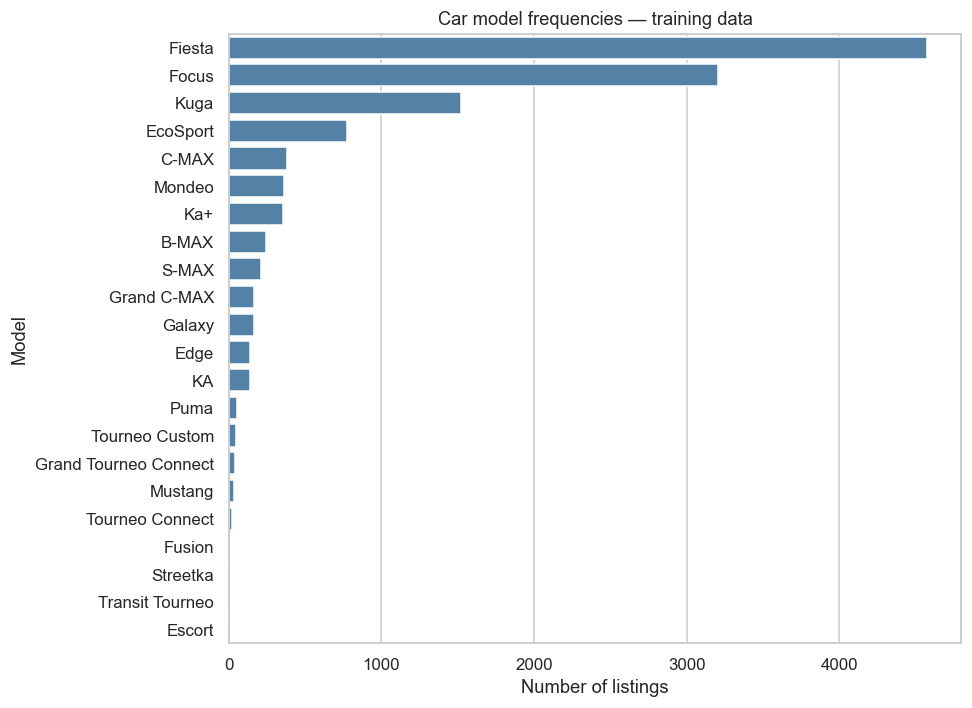

In [10]:
model_order = train_df["model"].value_counts().index
fig, ax = plt.subplots(figsize=(9, max(4, 0.3 * len(model_order))))
sns.countplot(data=train_df, y="model", order=model_order, color="steelblue", ax=ax)
ax.set(title="Car model frequencies — training data", xlabel="Number of listings", ylabel="Model")
fig.tight_layout()
plt.show()


**Read the result**

A high count means the model has more examples of that car model. It does not mean that model necessarily has a higher price or a smaller prediction error.


### 10. Plot transmission and fuel frequencies

- Compare the number of training listings for each transmission and fuel type.
- Counts describe representation in the sample, not the effect of a category on price.


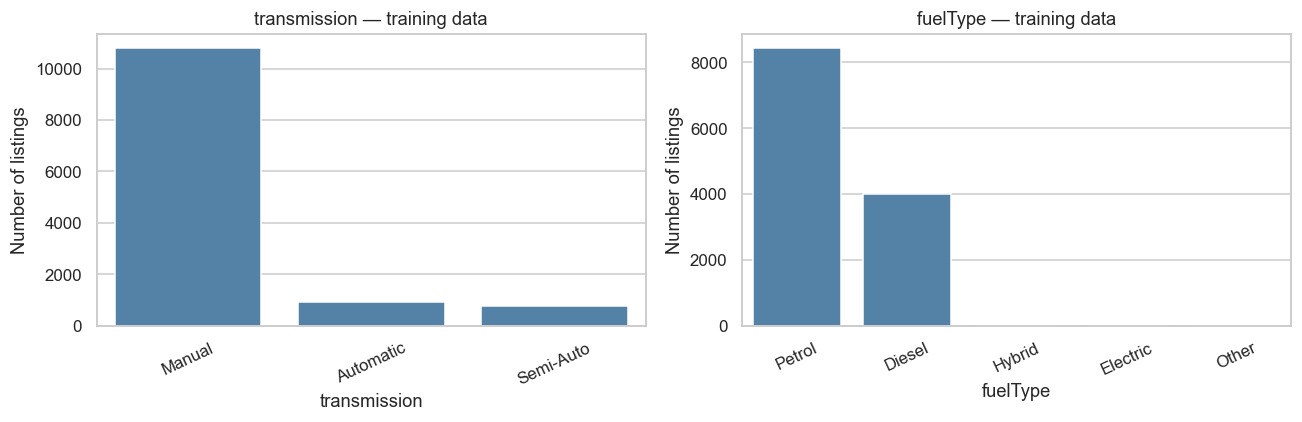

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column in zip(axes, ["transmission", "fuelType"]):
    sns.countplot(data=train_df, x=column, order=train_df[column].value_counts().index,
                  color="steelblue", ax=ax)
    ax.set(title=f"{column} — training data", xlabel=column, ylabel="Number of listings")
    ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
plt.show()


**Read the result**

Check for categories with very few examples. An unfamiliar category can appear in an evaluation fold even if it appeared somewhere in the complete dataset.


### 11. Compare price distributions across categories

- Use box plots to show medians, spread, and unusual prices instead of relying only on group means.
- Group differences are descriptive and may also reflect model, year, mileage, and other factors; they do not establish causality.


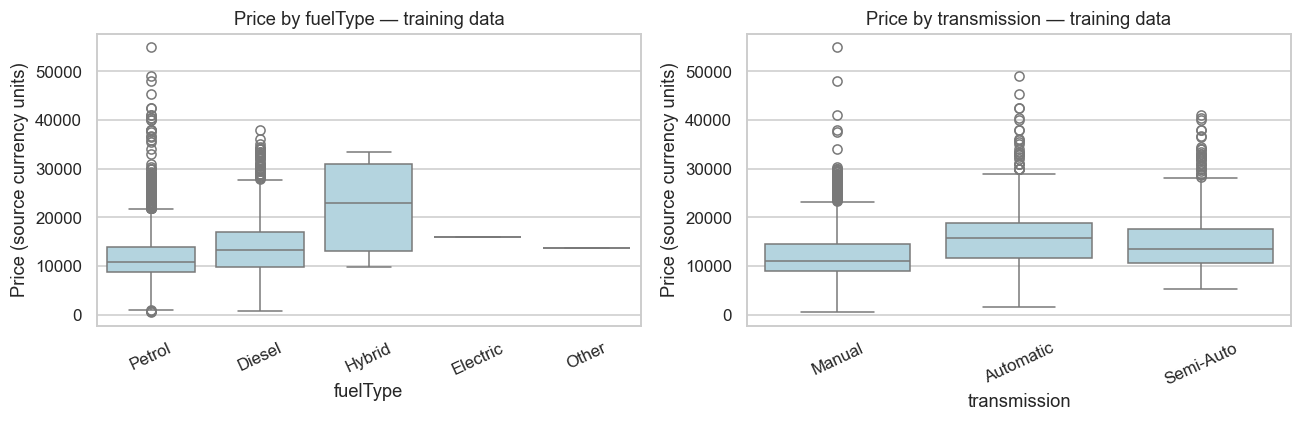

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column in zip(axes, ["fuelType", "transmission"]):
    sns.boxplot(data=train_df, x=column, y="price", color="lightblue", ax=ax)
    ax.set(title=f"Price by {column} — training data", xlabel=column, ylabel="Price (source currency units)")
    ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
plt.show()


**Read the result**

The line in each box is the median; the box spans the middle half of observations. Group differences can reflect model year, mileage, and other variables, so they are not causal effects.


### 12. Examine numeric correlations

- Compute Pearson correlations only for genuinely numeric variables; arbitrary category codes are not meaningful numeric measurements.
- Use a diverging heatmap with limits −1 to +1 and show correlations with price separately.
- Pandas uses available pairs when values are missing; these associations guide inspection, not causal interpretation or automatic feature deletion.


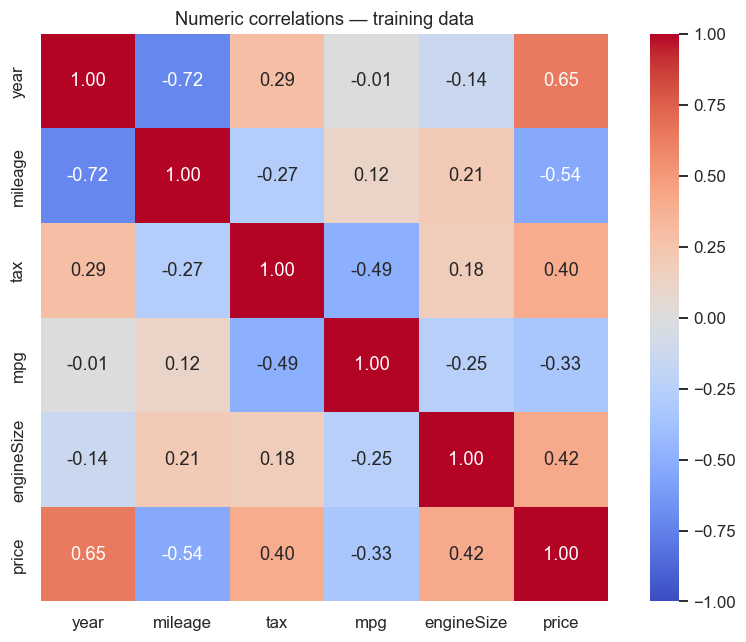

,Correlation with price
mileage,-0.536743
mpg,-0.330256
tax,0.401248
engineSize,0.416045
year,0.646045


In [13]:
numeric_correlation = train_df[numeric_features + [target_column]].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(numeric_correlation, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True, ax=ax)
ax.set_title("Numeric correlations — training data")
fig.tight_layout()
plt.show()
display(numeric_correlation["price"].drop("price").sort_values().to_frame("Correlation with price"))


**Read the result**

A negative correlation means one variable tends to decrease as the other increases. Pearson correlation describes pairwise linear association; an ANN may also learn nonlinear patterns and interactions.


### 13. Inspect year, mileage, and price

- Put predictors on the horizontal axis and price on the vertical axis.
- Show year and mileage separately to inspect the plausibility of a linear model; each plot is unadjusted for the other predictors.
- Use a fixed random sample of at most 3,000 training rows to keep plotting responsive.


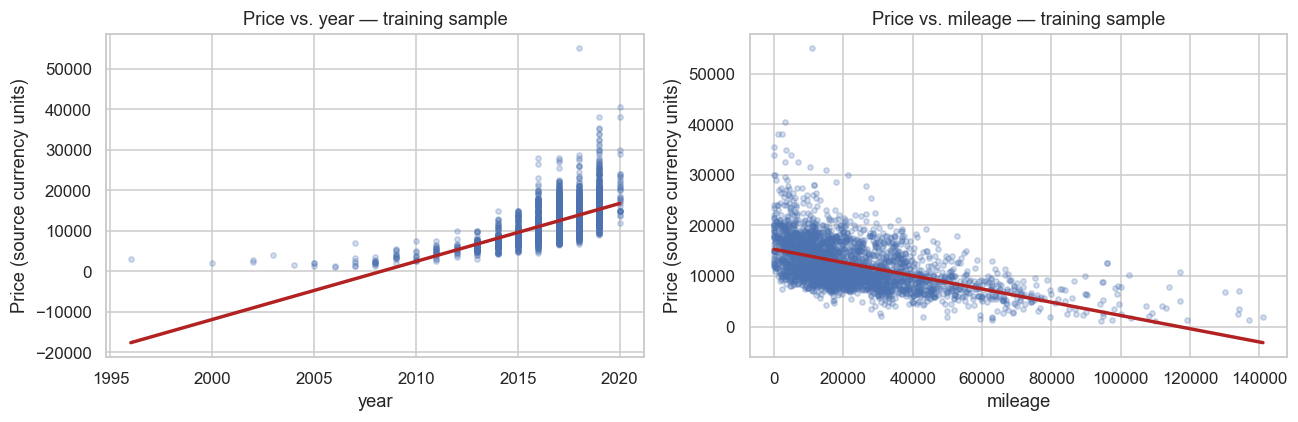

In [14]:
plot_df = train_df.sample(n=min(3000, len(train_df)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column in zip(axes, ["year", "mileage"]):
    sns.regplot(data=plot_df, x=column, y="price", ci=None,
                scatter_kws={"alpha": 0.25, "s": 12},
                line_kws={"color": "firebrick"}, ax=ax)
    ax.set(title=f"Price vs. {column} — training sample", ylabel="Price (source currency units)")
fig.tight_layout()
plt.show()


**Read the result**

The red lines summarize one predictor at a time. Curvature, changing spread, and interactions may motivate a nonlinear model, but only evaluation on unseen rows can establish whether it helps.


## Understand the ANN before training it

**Linear Regression** combines the prepared features additively:

$$\hat y = b_0 + \sum_{j=1}^{p} b_j z_j.$$

Here, $z$ contains standardized numeric features and one-hot category indicators. The ANN starts with the same information but learns intermediate representations. For the default two hidden layers:

$$h_1 = \operatorname{ReLU}(W_1z+b_1),\qquad
h_2 = \operatorname{ReLU}(W_2h_1+b_2),\qquad
\hat t = W_3h_2+b_3.$$

$$\operatorname{ReLU}(a)=\max(0,a),\qquad
t=\frac{y-\mu_y}{\sigma_y},\qquad
\hat y=\mu_y+\sigma_y\hat t.$$

- **Neuron:** calculates a weighted sum plus a bias, then applies an activation function.
- **Hidden layer:** a collection of neurons between the inputs and output. The defaults contain 64 and 32 neurons.
- **Activation:** ReLU introduces nonlinearity. Without nonlinear hidden activations, stacked affine layers still represent an affine function.
- **Output:** one linear output predicts a standardized continuous price. The inverse transformation restores source currency units.
- **Forward pass:** compute a prediction from input to output.
- **Loss:** quantify mismatch between predicted and true targets. Here the ANN uses a squared-error objective with L2 weight regularization.
- **Backpropagation:** compute gradients of the loss with respect to weights; the Adam optimizer uses those gradients to update them.
- **Batch:** the subset of fitting rows used for one parameter update. One epoch processes the entire fitting set once, usually in several batches.
- **Learning rate:** controls the update scale. **L2 regularization** discourages large weights. Both affect learning and generalization.
- **Early stopping:** monitor a separate validation subset and stop when meaningful improvement stalls. The test set is never used for this decision.

| Property | Ordinary Linear Regression | ANN used here |
|---|---|---|
| Relationship | Additive in the prepared features | Nonlinear functions and interactions |
| Training | Least-squares fitting | Repeated gradient updates with Adam |
| Numeric input scaling | Retained for consistency | Helps stable optimization |
| Target scaling | Original currency units | Standardized during fitting; restored for prediction |
| Controls | Feature representation | Layers, neurons, learning rate, L2 penalty, epochs |
| Main tradeoff | Simple and inexpensive | More flexible, with more training and overfitting risk |

Flexibility does not guarantee better predictions. Both models must earn their performance on the same held-out rows.

Implementation background: [scikit-learn's neural-network guide](https://scikit-learn.org/stable/modules/neural_networks_supervised.html).


### 14. Build one shared preprocessing specification

- Preserve the source workflow: median imputation and standardization for numeric columns; most-frequent imputation and one-hot encoding for nominal categories.
- Drop the first category in each categorical feature, as in the original LR notebook. Use exactly this representation for both LR and ANN.
- One-hot encoding usually produces more than eight input columns. The network's input dimension is learned from the fitting data.
- Keep independent fitted copies for each fold and model; never reuse a fitted transformer across evaluation folds.
- An unseen category is encoded as all zeros. With a dropped reference category, these encodings are indistinguishable; successful prediction does not establish reliability for that category.


In [15]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
    ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
], remainder="drop", verbose_feature_names_out=True)

print("Created an unfitted preprocessing specification.")


Created an unfitted preprocessing specification.


**Read the result**

No median, mean, standard deviation, or category vocabulary has been learned yet. Each later `.fit` or `.fit_transform` must receive only the appropriate fitting rows.


### 15. Define the Linear Regression and reference models

- Keep ordinary LR as the primary ANN comparator.
- Retain the source's log-target LR when `RUN_LOG_LR_REFERENCE=True`. It learns `log1p(price)` and returns predictions through `expm1`.
- A log transformation changes the error objective. Its inverse-transformed prediction is not automatically an unbiased conditional mean price.
- Fit the median baseline from training targets only. It provides a useful MAE reference; a mean baseline would minimize training squared error among constant predictions.
- Every included model will be evaluated on the same cross-validation folds and the same final test rows.


In [16]:
lr_template = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("regressor", LinearRegression())
])
reference_templates = {"Linear Regression": lr_template}
if RUN_LOG_LR_REFERENCE:
    reference_templates["Log-target Linear Regression"] = TransformedTargetRegressor(
        regressor=clone(lr_template), func=np.log1p, inverse_func=np.expm1
    )
reference_templates["Median baseline"] = DummyRegressor(strategy="median")

model_order = ["Linear Regression", "ANN"]
if RUN_LOG_LR_REFERENCE:
    model_order.append("Log-target Linear Regression")
model_order.append("Median baseline")
primary_models = ["Linear Regression", "ANN"]
print("Models:", model_order)


Models: ['Linear Regression', 'ANN', 'Log-target Linear Regression', 'Median baseline']


**Read the result**

These are unfitted model templates. Cloning a template for each fold prevents one fitted state from influencing another fold.


### 16. Define the regression metrics before looking at results

Let $e_i=y_i-\hat y_i$ denote a residual. Positive residuals indicate underprediction.

| Metric | Definition | Unit / interpretation | Preferred direction |
|---|---|---|---|
| MAE | $\frac{1}{n}\sum_i \lvert e_i\rvert$ | Average absolute error, currency units | Lower |
| MSE | $\frac{1}{n}\sum_i e_i^2$ | Squared currency units; emphasizes large errors | Lower |
| RMSE | $\sqrt{\frac{1}{n}\sum_i e_i^2}$ | Large-error-sensitive error, currency units | Lower |
| R² | $1-\frac{\sum_i e_i^2}{\sum_i(y_i-\bar y)^2}$ | Unitless; can be negative | Higher |
| Median AE | $\operatorname{median}_i \lvert e_i\rvert$ | Robust typical absolute error, currency units | Lower |
| MAPE (%) | $\frac{100}{n}\sum_i\lvert e_i/y_i\rvert$ | Relative error; can overemphasize cheap cars | Lower |
| P90 AE | 90th percentile of $\lvert e_i\rvert$ | Tail error magnitude, currency units | Lower |
| Mean residual | $\frac{1}{n}\sum_i e_i$ | Direction of bias, currency units | Closer to zero |

- R² is not classification accuracy. R² is undefined when the evaluation targets do not vary.
- Cleaning requires positive prices, so MAPE is defined here. We multiply scikit-learn's relative MAPE value by 100 for a percentage.
- On one fixed evaluation set, **MSE, RMSE, and R² produce the same ranking**; they are not three independent pieces of evidence.
- A mean residual near zero can hide large positive and negative errors that cancel. Read it with MAE and RMSE.
- Predictions are not clipped. This keeps the reported models and their failure modes visible.

Reference: [scikit-learn regression metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics).


In [17]:
def regression_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float).ravel()
    predicted = np.asarray(predicted, dtype=float).ravel()
    if actual.shape != predicted.shape or actual.size == 0:
        raise ValueError("Actual values and predictions need matching, nonempty shapes.")
    if not (np.isfinite(actual).all() and np.isfinite(predicted).all()):
        raise ValueError("Metrics require finite actual values and predictions.")
    residuals = actual - predicted
    absolute_errors = np.abs(residuals)
    mse = mean_squared_error(actual, predicted)
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(actual, predicted) if np.unique(actual).size > 1 else np.nan,
        "Median AE": median_absolute_error(actual, predicted),
        "MAPE (%)": 100 * mean_absolute_percentage_error(actual, predicted)
                    if np.all(actual > 0) else np.nan,
        "P90 AE": np.percentile(absolute_errors, 90),
        "Mean residual": residuals.mean()
    }

metric_precision = {name: 2 for name in
                  ["MAE", "MSE", "RMSE", "Median AE", "MAPE (%)", "P90 AE", "Mean residual"]}
metric_precision["R2"] = 4
print("Eight regression metrics are ready; RMSE is the primary metric.")


Eight regression metrics are ready; RMSE is the primary metric.


**Read the result**

All calls to this function will receive prices in original currency units, including ANN predictions after inverse target scaling. Training time and negative-prediction counts are reported separately.


### 17. Create a fresh ANN for one training run

- Use two hidden layers with ReLU, Adam, and L2 regularization. The default squared-error regression output is linear.
- `partial_fit` performs one epoch per call and preserves learned weights and the optimizer state for the next call.
- Use an advancing random-number generator for reproducible initialization and shuffling across epochs.
- Disable scikit-learn's internal early stopping because we explicitly split raw fitting/validation rows **before** learning any imputation, encoding, input scaling, or target scaling.
- The next two helper sections expose training steps so students can inspect them. The longer functions package the same procedure for every CV fold.


In [18]:
def make_ann(n_fitting_rows, seed):
    return MLPRegressor(
        hidden_layer_sizes=ANN_HIDDEN_LAYERS,
        activation="relu",
        solver="adam",
        alpha=ANN_ALPHA,
        batch_size=min(ANN_BATCH_SIZE, n_fitting_rows),
        learning_rate_init=ANN_LEARNING_RATE,
        max_iter=1,
        early_stopping=False,
        shuffle=True,
        tol=0.0,
        n_iter_no_change=ANN_MAX_EPOCHS + 1,
        random_state=np.random.RandomState(seed)
    )

print("Fresh ANN factory ready. Training will use one partial_fit call per epoch.")


Fresh ANN factory ready. Training will use one partial_fit call per epoch.


**Read the result**

Setting `max_iter=1` is deliberate: our explicit epoch loop controls training duration. The output is a real regression ANN implemented with scikit-learn, not a renamed linear model.


### 18. Select the ANN epoch count with an isolated validation set

1. Split raw rows from the supplied training pool into inner fitting and validation subsets.
2. Fit a fresh preprocessor and target scaler on the **inner fitting subset only**.
3. Train one epoch, then measure fitting and validation RMSE.
4. Record the epoch with the lowest validation RMSE. Stop after `ANN_PATIENCE` epochs without an improvement of at least `ANN_MIN_DELTA` in standardized validation RMSE, or at the maximum epoch budget.

- The best-epoch record tracks every new minimum; the patience counter requires a meaningful improvement. These are separate decisions.
- Returned curves show original-currency RMSE; standardized RMSE is used only for a scale-independent stopping threshold.
- No outer CV evaluation rows and no final test rows enter this helper.


In [19]:
def select_ann_epochs(X_pool, y_pool, seed):
    X_fit, X_val, y_fit, y_val = train_test_split(
        X_pool, y_pool, test_size=ANN_VALIDATION_SIZE, random_state=seed
    )
    if y_fit.nunique() < 2 or len(X_val) < 2:
        raise ValueError("ANN epoch selection needs varied fitting prices and at least two validation rows.")

    inner_preprocessor = clone(preprocessor)
    target_scaler = StandardScaler()
    history_rows = []
    best_rmse_scaled = np.inf
    patience_reference = np.inf
    best_epoch = 1
    epochs_without_improvement = 0
    stop_reason = "Maximum epoch budget reached"

    with threadpool_limits(limits=1):
        Z_fit = inner_preprocessor.fit_transform(X_fit)
        Z_val = inner_preprocessor.transform(X_val)
        t_fit = target_scaler.fit_transform(np.asarray(y_fit).reshape(-1, 1)).ravel()
        t_val = target_scaler.transform(np.asarray(y_val).reshape(-1, 1)).ravel()
        price_scale = float(target_scaler.scale_[0])
        network = make_ann(len(X_fit), seed)

        for epoch in range(1, ANN_MAX_EPOCHS + 1):
            network.partial_fit(Z_fit, t_fit)
            fitting_rmse_scaled = np.sqrt(mean_squared_error(t_fit, network.predict(Z_fit)))
            validation_rmse_scaled = np.sqrt(mean_squared_error(t_val, network.predict(Z_val)))
            history_rows.append({
                "Epoch": epoch,
                "Fitting RMSE": fitting_rmse_scaled * price_scale,
                "Validation RMSE": validation_rmse_scaled * price_scale,
                "Standardized training objective": float(network.loss_)
            })

            if validation_rmse_scaled < best_rmse_scaled:
                best_rmse_scaled = validation_rmse_scaled
                best_epoch = epoch
            if validation_rmse_scaled < patience_reference - ANN_MIN_DELTA:
                patience_reference = validation_rmse_scaled
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1
            if epochs_without_improvement >= ANN_PATIENCE:
                stop_reason = "Validation patience exhausted"
                break

    history = pd.DataFrame(history_rows)
    selection_info = {
        "selected_epochs": int(best_epoch),
        "epochs_observed": int(len(history)),
        "inner_fit_rows": len(X_fit),
        "inner_validation_rows": len(X_val),
        "stop_reason": stop_reason,
        "best_validation_rmse": best_rmse_scaled * price_scale
    }
    return best_epoch, history, selection_info

print("Validation-based epoch selection helper ready.")


Validation-based epoch selection helper ready.


**Read the result**

The minimum validation error is used for development, so it is not an unbiased final performance estimate. The outer CV rows and final test rows provide separate evaluations of the completed training procedure.


### 19. Refit on the entire training pool and restore price units

- After selecting the epoch count, create **new** preprocessing, a **new** target scaler, and a **new** ANN.
- Fit these on the whole supplied training pool for exactly the selected number of epochs. This allows both final LR and final ANN to use the same 70% training rows.
- This is a fresh refit, not restoration of the inner model's best weights. The final weights and category vocabulary can differ.
- Transferring an epoch count is a training-budget heuristic: more rows mean more batch updates per epoch, so that count is not guaranteed to be optimal for the full-pool refit. Outer CV evaluates this complete procedure.
- Return the fitted components together in an ANN bundle. Prediction always applies its fitted preprocessing and inverse target transformation.
- Report the cost of epoch selection **and** refitting as total ANN training time.


In [20]:
def fit_ann_fixed_epochs(X_pool, y_pool, epochs, seed):
    fitted_preprocessor = clone(preprocessor)
    target_scaler = StandardScaler()
    refit_objectives = []
    with threadpool_limits(limits=1):
        Z_pool = fitted_preprocessor.fit_transform(X_pool)
        t_pool = target_scaler.fit_transform(np.asarray(y_pool).reshape(-1, 1)).ravel()
        network = make_ann(len(X_pool), seed)
        for epoch in range(epochs):
            network.partial_fit(Z_pool, t_pool)
            refit_objectives.append(float(network.loss_))
    return {
        "preprocessor": fitted_preprocessor,
        "target_scaler": target_scaler,
        "network": network,
        "epochs": int(epochs),
        "refit_objectives": refit_objectives
    }


def fit_ann_with_validation(X_pool, y_pool, seed=RANDOM_STATE):
    started = perf_counter()
    epochs, history, info = select_ann_epochs(X_pool, y_pool, seed)
    selection_seconds = perf_counter() - started
    refit_started = perf_counter()
    bundle = fit_ann_fixed_epochs(X_pool, y_pool, epochs, seed)
    refit_seconds = perf_counter() - refit_started
    info.update({"selection_seconds": selection_seconds,
                 "refit_seconds": refit_seconds,
                 "total_fit_seconds": perf_counter() - started})
    return bundle, history, info


def predict_ann(bundle, raw_features):
    with threadpool_limits(limits=1):
        Z = bundle["preprocessor"].transform(raw_features)
        standardized_prediction = bundle["network"].predict(Z)
    return bundle["target_scaler"].inverse_transform(
        standardized_prediction.reshape(-1, 1)
    ).ravel()

print("ANN fitting and original-price prediction helpers ready.")


ANN fitting and original-price prediction helpers ready.


**Read the result**

The feature scaler and target scaler have different jobs. Standardizing the target helps numerical optimization; it does not change the units of the final reported predictions.


### 20. Cross-validate all models on identical training folds

- Generate the fold indices once from the 70% training pool, then reuse them for every model.
- Fit LR and its references on each outer training fold. ANN epoch selection uses a further split within that same outer training fold, followed by a full outer-training-fold refit.
- Only the outer validation fold is used for that fold's reported metrics.
- This explicit loop replaces the source's single-model `cross_validate` call so that the ANN's inner training procedure remains visible.
- Architecture, optimizer, and regularization settings remain fixed. Only the ANN epoch count is selected within each fold.
- Unknown-category warnings may appear for rare categories; they describe the encoder behavior explained above.


In [21]:
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(cv.split(X_train, y_train))
cv_rows = []
cv_ann_rows = []

for fold, (fit_positions, validation_positions) in enumerate(cv_splits, start=1):
    X_fold_fit = X_train.iloc[fit_positions]
    y_fold_fit = y_train.iloc[fit_positions]
    X_fold_validation = X_train.iloc[validation_positions]
    y_fold_validation = y_train.iloc[validation_positions]
    assert X_fold_fit.index.intersection(X_fold_validation.index).empty

    for name, template in reference_templates.items():
        started = perf_counter()
        with threadpool_limits(limits=1):
            fitted = clone(template).fit(X_fold_fit, y_fold_fit)
        fit_seconds = perf_counter() - started
        predicted = fitted.predict(X_fold_validation)
        cv_rows.append({"Fold": fold, "Model": name,
                        **regression_metrics(y_fold_validation, predicted),
                        "Fit seconds": fit_seconds})

    fold_ann, fold_history, fold_info = fit_ann_with_validation(
        X_fold_fit, y_fold_fit, seed=RANDOM_STATE + fold
    )
    predicted = predict_ann(fold_ann, X_fold_validation)
    cv_rows.append({"Fold": fold, "Model": "ANN",
                    **regression_metrics(y_fold_validation, predicted),
                    "Fit seconds": fold_info["total_fit_seconds"]})
    cv_ann_rows.append({"Fold": fold, **fold_info})
    print(f"Completed fold {fold}/{CV_FOLDS}; ANN selected "
          f"{fold_info['selected_epochs']} epochs.")

cv_results = pd.DataFrame(cv_rows)
cv_ann_details = pd.DataFrame(cv_ann_rows)


Completed fold 1/5; ANN selected 121 epochs.


c:\Users\user\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning: Found unknown categories in columns [0, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\user\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning: Found unknown categories in columns [0, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\user\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning: Found unknown categories in columns [0, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Completed fold 2/5; ANN selected 45 epochs.
Completed fold 3/5; ANN selected 88 epochs.


c:\Users\user\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning: Found unknown categories in columns [0, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Completed fold 4/5; ANN selected 48 epochs.


c:\Users\user\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Completed fold 5/5; ANN selected 92 epochs.


**Read the result**

Every model is evaluated on the same rows in each fold. ANN fit time includes its extra validation work, so it measures the cost of this full learning procedure rather than one network update alone.


### 21. Summarize cross-validation before opening the test set

- Report the mean and sample standard deviation of fold MAE, RMSE, R², MAPE, and fit time.
- Fold standard deviations describe variability; they are **not** confidence intervals, because the training folds overlap.
- Record which of LR and ANN has lower mean CV RMSE before seeing the test results.
- If you tune additional settings using these same fold scores, the selected CV score becomes optimistic. Use a further nested search or fresh evaluation data when an unbiased tuning assessment is required.


MAE              RMSE             R2  \
                                  mean     std      mean     std   mean   
Model                                                                     
Linear Regression             1365.753  14.270  1860.699  63.915  0.846   
ANN                            855.477  24.629  1248.248  79.657  0.930   
Log-target Linear Regression  1161.994  15.651  1656.302  64.328  0.878   
Median baseline               3617.923  20.190  4837.803  39.079 -0.042   

                                    MAPE (%)        Fit seconds         
                                std     mean    std        mean    std  
Model                                                                   
Linear Regression             0.011   13.914  0.573       0.041  0.023  
ANN                           0.009    7.394  0.390       3.094  1.004  
Log-target Linear Regression  0.010    9.829  0.200       0.031  0.000  
Median baseline               0.004   35.117  1.100       0.014  0.000

,Fold,selected_epochs,epochs_observed,stop_reason
0,1,121,123,Validation patience exhausted
1,2,45,66,Validation patience exhausted
2,3,88,113,Validation patience exhausted
3,4,48,73,Validation patience exhausted
4,5,92,117,Validation patience exhausted


Primary model preferred by training-only CV RMSE: ANN


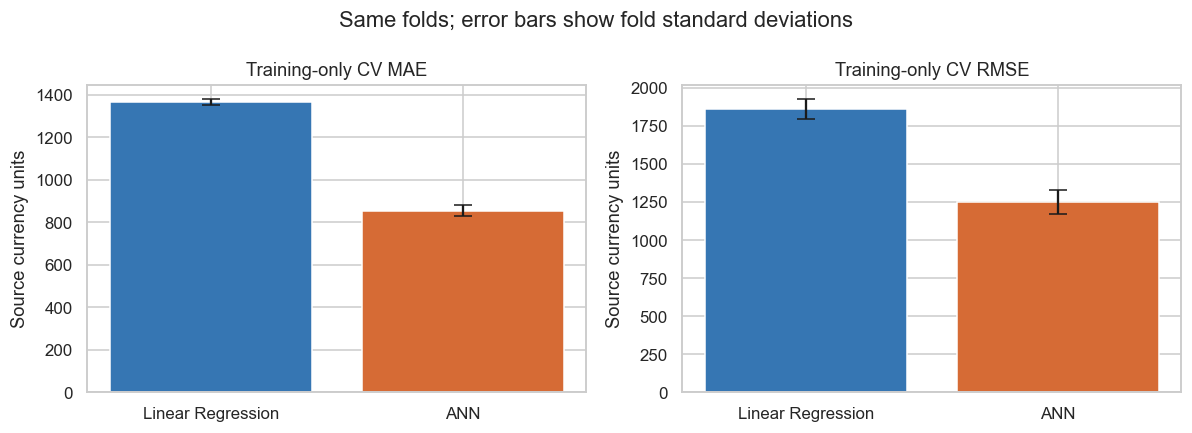

In [22]:
cv_summary = cv_results.groupby("Model")[
    ["MAE", "RMSE", "R2", "MAPE (%)", "Fit seconds"]
].agg(["mean", "std"]).reindex(model_order)
display(cv_summary.round(3))
display(cv_ann_details[["Fold", "selected_epochs", "epochs_observed", "stop_reason"]])

preferred_by_cv = cv_summary.loc[primary_models, ("RMSE", "mean")].idxmin()
print(f"Primary model preferred by training-only CV RMSE: {preferred_by_cv}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    means = cv_summary.loc[primary_models, (metric, "mean")]
    deviations = cv_summary.loc[primary_models, (metric, "std")]
    ax.bar(primary_models, means, yerr=deviations, capsize=6,
           color=[COLORS[name] for name in primary_models])
    ax.set(title=f"Training-only CV {metric}", ylabel="Source currency units")
fig.suptitle("Same folds; error bars show fold standard deviations")
fig.tight_layout()
plt.show()


**Read the result**

A lower mean error favors that model under this CV setup. Small differences relative to fold-to-fold variability deserve caution. The preferred model is recorded without consulting the final test set.


### 22. Fit the final models on the full training pool

- Refit every reference model on all training rows.
- Run ANN epoch selection within the full training pool, then refit the ANN on that entire pool for its selected epoch count.
- Keep the final test set unopened for all fitting and stopping decisions.
- Report selection and refit time separately for ANN, as well as total fit time for the model comparison.


In [23]:
fitted_references = {}
fit_times = {}
for name, template in reference_templates.items():
    started = perf_counter()
    with threadpool_limits(limits=1):
        fitted_references[name] = clone(template).fit(X_train, y_train)
    fit_times[name] = perf_counter() - started

ann_bundle, ann_history, ann_info = fit_ann_with_validation(X_train, y_train)
fit_times["ANN"] = ann_info["total_fit_seconds"]

print(f"Final ANN refit epochs: {ann_info['selected_epochs']}")
print("Epoch-selection stopping reason:", ann_info["stop_reason"])
print(f"ANN selection: {ann_info['selection_seconds']:.2f} s; "
      f"refit: {ann_info['refit_seconds']:.2f} s.")
display(pd.Series(fit_times, name="Total fit seconds").reindex(model_order).to_frame())


Final ANN refit epochs: 63
Epoch-selection stopping reason: Validation patience exhausted
ANN selection: 1.93 s; refit: 1.41 s.


,Total fit seconds
Linear Regression,0.036696
ANN,3.333334
Log-target Linear Regression,0.034885
Median baseline,0.014599


**Read the result**

The ANN and LR have now both fitted their final models using all training records. The inner validation minimum helped choose the training budget; it is not the final test score.


### 23. Inspect ANN learning and the selected epoch

- The first panel shows fitting and validation RMSE during the temporary inner split of the final training pool.
- Mark the selected minimum-validation-error epoch, which may be earlier than the last observed epoch.
- The second panel shows the final full-training refit's standardized squared-error-plus-regularization objective. Its scale differs from currency-unit RMSE.
- These are epoch learning curves. No test errors are monitored during training.


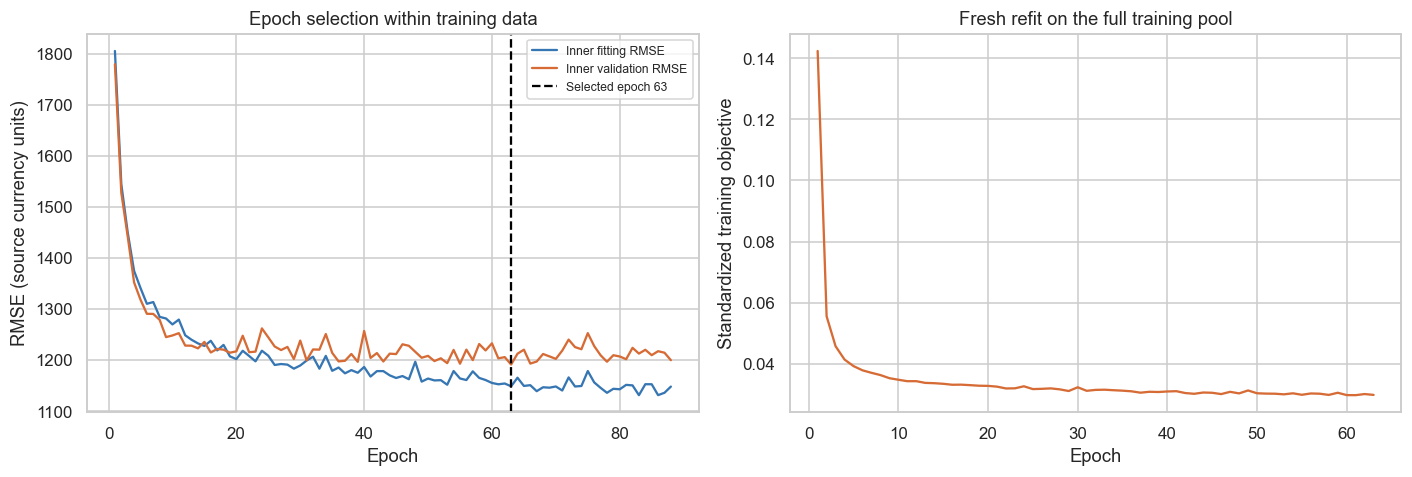

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ann_history["Epoch"], ann_history["Fitting RMSE"], label="Inner fitting RMSE",
             color=COLORS["Linear Regression"])
axes[0].plot(ann_history["Epoch"], ann_history["Validation RMSE"], label="Inner validation RMSE",
             color=COLORS["ANN"])
axes[0].axvline(ann_info["selected_epochs"], color="black", linestyle="--",
                label=f"Selected epoch {ann_info['selected_epochs']}")
axes[0].set(title="Epoch selection within training data", xlabel="Epoch",
             ylabel="RMSE (source currency units)")
axes[0].legend(fontsize=8)

axes[1].plot(np.arange(1, ann_bundle["epochs"] + 1), ann_bundle["refit_objectives"],
             color=COLORS["ANN"])
axes[1].set(title="Fresh refit on the full training pool", xlabel="Epoch",
             ylabel="Standardized training objective")
fig.tight_layout()
plt.show()


**Read the result**

If fitting error keeps falling while validation error rises, the inner network may be overfitting. If both remain high, it may be underfitting or poorly optimized. The final refit has different weights, so the first panel is not its validation history.


### 24. Inspect the actual ANN architecture and parameter count

- Obtain the input dimension from the fitted preprocessor instead of assuming eight ANN inputs.
- Show a schematic with the true layer sizes in the labels. Only representative neurons are drawn in large layers.
- Count every fitted weight and bias directly. A layer with $a$ inputs and $b$ outputs has $ab+b$ trainable parameters.
- The final linear output is standardized price; inverse target scaling converts it to currency units.


,Connection,Weight shape,Weights,Biases,Parameters
0,Layer 0 → layer 1,"(32, 64)",2048,64,2112
1,Layer 1 → layer 2,"(64, 32)",2048,32,2080
2,Layer 2 → layer 3,"(32, 1)",32,1,33


Total trainable parameters: 4225
Output activation: identity
Prepared input features: ['numeric__year', 'numeric__mileage', 'numeric__tax', 'numeric__mpg', 'numeric__engineSize', 'categorical__model_C-MAX', 'categorical__model_EcoSport', 'categorical__model_Edge', 'categorical__model_Escort', 'categorical__model_Fiesta', 'categorical__model_Focus', 'categorical__model_Fusion', 'categorical__model_Galaxy', 'categorical__model_Grand C-MAX', 'categorical__model_Grand Tourneo Connect', 'categorical__model_KA', 'categorical__model_Ka+', 'categorical__model_Kuga', 'categorical__model_Mondeo', 'categorical__model_Mustang', 'categorical__model_Puma', 'categorical__model_S-MAX', 'categorical__model_Streetka', 'categorical__model_Tourneo Connect', 'categorical__model_Tourneo Custom', 'categorical__model_Transit Tourneo', 'categorical__transmission_Manual', 'categorical__transmission_Semi-Auto', 'categorical__fuelType_Electric', 'categorical__fuelType_Hybrid', 'categorical__fuelType_Other', 'cate

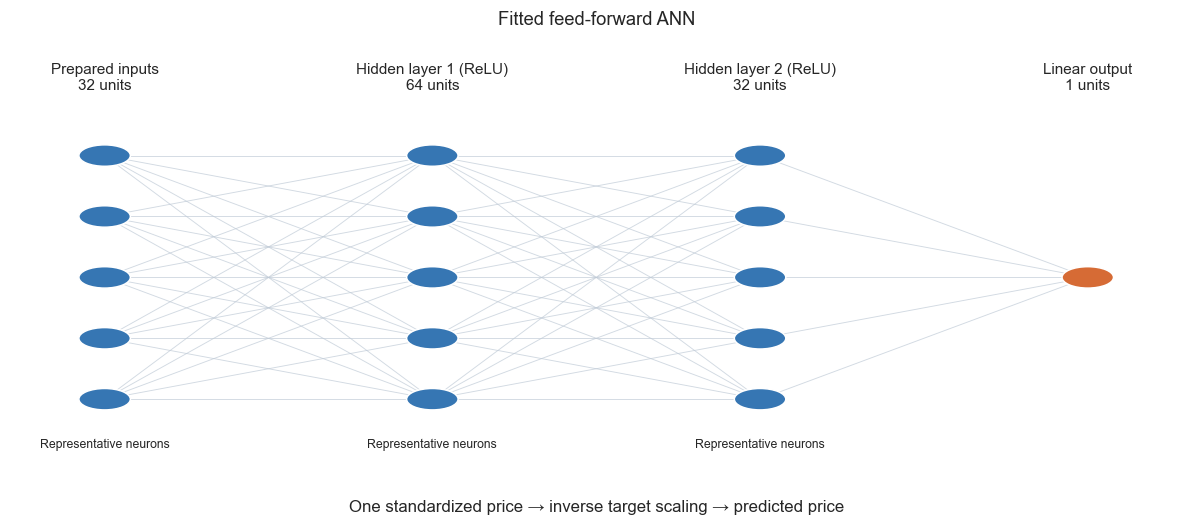

In [25]:
network = ann_bundle["network"]
encoded_names = ann_bundle["preprocessor"].get_feature_names_out()
layer_sizes = [len(encoded_names), *ANN_HIDDEN_LAYERS, 1]
parameter_rows = []
for layer, (weights, biases) in enumerate(zip(network.coefs_, network.intercepts_), start=1):
    parameter_rows.append({"Connection": f"Layer {layer - 1} → layer {layer}",
                           "Weight shape": str(weights.shape),
                           "Weights": weights.size, "Biases": biases.size,
                           "Parameters": weights.size + biases.size})
parameter_table = pd.DataFrame(parameter_rows)
display(parameter_table)
print("Total trainable parameters:", int(parameter_table["Parameters"].sum()))
print("Output activation:", network.out_activation_)
print("Prepared input features:", list(encoded_names))

fig, ax = plt.subplots(figsize=(11, 5))
x_positions = np.linspace(0.08, 0.92, len(layer_sizes))
positions = []
for x_position, size in zip(x_positions, layer_sizes):
    shown = min(size, 5)
    y_positions = np.linspace(0.25, 0.75, shown) if shown > 1 else np.array([0.5])
    positions.append([(x_position, position) for position in y_positions])
for left, right in zip(positions[:-1], positions[1:]):
    for start in left:
        for end in right:
            ax.plot([start[0], end[0]], [start[1], end[1]], color="#BFCAD6",
                     alpha=0.7, linewidth=0.6, zorder=1)
for layer, neurons in enumerate(positions):
    for x_position, y_position in neurons:
        ax.add_patch(Circle((x_position, y_position), 0.022,
                            facecolor="#D66B35" if layer == len(positions) - 1 else "#3676B3",
                            edgecolor="white", linewidth=1.0, zorder=2))
    title = "Prepared inputs" if layer == 0 else (
        "Linear output" if layer == len(positions) - 1 else f"Hidden layer {layer} (ReLU)")
    ax.text(x_positions[layer], 0.91, f"{title}\n{layer_sizes[layer]} units",
            ha="center", va="center", fontsize=10)
    if layer_sizes[layer] > 5:
        ax.text(x_positions[layer], 0.15, "Representative neurons", ha="center", fontsize=8)
ax.text(0.5, 0.02, "One standardized price → inverse target scaling → predicted price",
        ha="center", fontsize=11)
ax.set(xlim=(0, 1), ylim=(0, 1), title="Fitted feed-forward ANN")
ax.axis("off")
fig.tight_layout()
plt.show()


**Read the result**

Parameter count describes model size, not predictive quality. More parameters can represent more complex patterns, but they also require enough data and appropriate regularization.


### 25. Evaluate every final model on the same held-out test set

- Open the test set only after the model specifications and final fits are complete.
- Apply each fitted model to exactly `X_test`, in the same row order, and calculate all eight metrics against `y_test`.
- Also compute training metrics to diagnose an unusually large train–test gap. Training errors are optimistic performance estimates.
- Record negative predictions without clipping them.
- Prediction timing is a single batch measurement, including preprocessing and any target inverse transformation. It is a rough comparison, not a production latency benchmark.


In [26]:
def predict_model(name, raw_features):
    if name == "ANN":
        return predict_ann(ann_bundle, raw_features)
    with threadpool_limits(limits=1):
        return fitted_references[name].predict(raw_features)


test_predictions = {}
train_predictions = {}
prediction_times = {}
for name in model_order:
    started = perf_counter()
    test_predictions[name] = np.asarray(predict_model(name, X_test)).ravel()
    prediction_times[name] = perf_counter() - started
    train_predictions[name] = np.asarray(predict_model(name, X_train)).ravel()

test_metrics = pd.DataFrame({
    name: regression_metrics(y_test, test_predictions[name]) for name in model_order
}).T
test_metrics.index.name = "Model"
train_metrics = pd.DataFrame({
    name: regression_metrics(y_train, train_predictions[name]) for name in model_order
}).T
train_metrics.index.name = "Model"
print("Final held-out test metrics")
display(test_metrics.round(metric_precision))

generalization = pd.DataFrame({
    "Train MAE": train_metrics["MAE"], "Test MAE": test_metrics["MAE"],
    "Train RMSE": train_metrics["RMSE"], "Test RMSE": test_metrics["RMSE"],
    "Train R2": train_metrics["R2"], "Test R2": test_metrics["R2"]
})
display(generalization.round(3))
cost_and_validity = pd.DataFrame({
    "Total fit seconds": pd.Series(fit_times),
    "Test batch prediction seconds": pd.Series(prediction_times),
    "Negative test predictions": pd.Series({
        name: int((test_predictions[name] < 0).sum()) for name in model_order
    })
}).reindex(model_order)
display(cost_and_validity.round(4))


Final held-out test metrics


c:\Users\user\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\user\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\user\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,MAE,MSE,RMSE,R2,Median AE,MAPE (%),P90 AE,Mean residual
Model,,,,,,,,
Linear Regression,1343.96,3257817.66,1804.94,0.8541,1077.61,13.34,2719.62,2.09
ANN,836.45,1427129.46,1194.63,0.9361,631.99,7.27,1753.08,-115.68
Log-target Linear Regression,1141.58,2560247.95,1600.08,0.8854,882.63,9.60,2323.64,116.84
Median baseline,3595.81,23319857.29,4829.06,-0.0441,2807.00,33.72,7495.80,992.91


,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2
Model,,,,,,
Linear Regression,1358.807,1343.962,1843.931,1804.943,0.849,0.854
ANN,801.062,836.447,1144.586,1194.625,0.942,0.936
Log-target Linear Regression,1155.900,1141.580,1641.266,1600.077,0.880,0.885
Median baseline,3617.872,3595.805,4837.342,4829.064,-0.041,-0.044


,Total fit seconds,Test batch prediction seconds,Negative test predictions
Linear Regression,0.0367,0.0211,42
ANN,3.3333,0.0210,0
Log-target Linear Regression,0.0349,0.0196,0
Median baseline,0.0146,0.0141,0


**Read the result**

Read RMSE and MAE first, then relative error, tail error, and bias. A negative predicted price is a visible limitation of an unconstrained model. Any decision to change the model after viewing these diagnostics requires fresh evaluation data for an unbiased new test.


### 26. Visualize the main LR-versus-ANN metric comparison

- Use separate panels because the metrics have different units and scales.
- Lower MAE, RMSE, and MAPE are better; higher R² is better.
- The numerical table also includes MSE, median absolute error, tail error, and bias without squeezing unrelated units onto one axis.


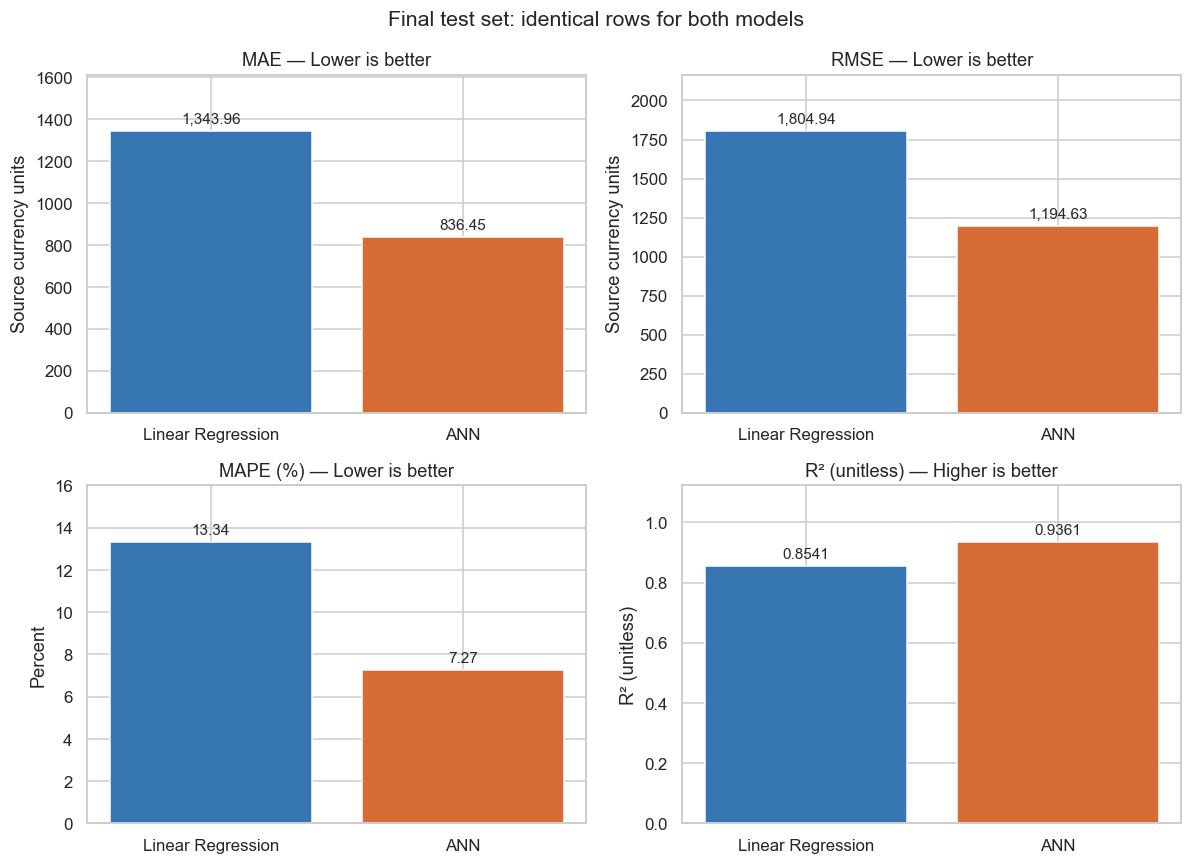

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
plot_specs = [("MAE", "Source currency units", "Lower is better"),
              ("RMSE", "Source currency units", "Lower is better"),
              ("MAPE (%)", "Percent", "Lower is better"),
              ("R2", "R² (unitless)", "Higher is better")]
for ax, (metric, units, direction) in zip(axes.ravel(), plot_specs):
    values = test_metrics.loc[primary_models, metric].to_numpy()
    bars = ax.bar(primary_models, values, color=[COLORS[name] for name in primary_models])
    ax.set(title=f"{units if metric == 'R2' else metric} — {direction}", ylabel=units)
    ax.axhline(0, color="#666666", linewidth=0.8)
    ax.margins(y=0.2)
    for bar, value in zip(bars, values):
        if np.isfinite(value):
            label = f"{value:.4f}" if metric == "R2" else f"{value:,.2f}"
            ax.annotate(label, (bar.get_x() + bar.get_width() / 2, value),
                        xytext=(0, 5 if value >= 0 else -13), textcoords="offset points",
                        ha="center", fontsize=10)
fig.suptitle("Final test set: identical rows for both models", fontsize=14)
fig.tight_layout()
plt.show()


**Read the result**

The ANN may improve some metrics and worsen others. For example, lower median error with higher RMSE can indicate better typical predictions but a few larger failures.


### 27. Calculate the ANN improvement and a data-driven conclusion

- For each nonnegative error metric, define ANN error reduction as $100(\text{LR}-\text{ANN})/\text{LR}$. A positive value favors ANN; a negative value favors LR.
- Report R² as an absolute difference, not a percentage improvement.
- Use absolute mean residual when discussing bias magnitude, because the signed bias itself can be positive or negative.
- State which primary model was preferred by training CV and describe the observed test comparison separately.
- The printed conclusion is generated from measured values; ANN is not assumed to win.


In [28]:
error_metric_names = ["MAE", "MSE", "RMSE", "Median AE", "MAPE (%)", "P90 AE"]
comparison_rows = []
for metric in error_metric_names:
    lr_value = float(test_metrics.loc["Linear Regression", metric])
    ann_value = float(test_metrics.loc["ANN", metric])
    comparison_rows.append({"Metric": metric, "Linear Regression": lr_value,
                            "ANN": ann_value, "ANN minus LR": ann_value - lr_value,
                            "ANN error reduction (%)": 100 * (lr_value - ann_value) / lr_value
                            if lr_value > 0 else np.nan})
primary_comparison = pd.DataFrame(comparison_rows).set_index("Metric")
display(primary_comparison.round(3))

lr_rmse = float(test_metrics.loc["Linear Regression", "RMSE"])
ann_rmse = float(test_metrics.loc["ANN", "RMSE"])
if np.isclose(lr_rmse, ann_rmse, rtol=1e-6, atol=1e-8):
    print("The two primary models have essentially equal test RMSE at the stated numerical tolerance.")
else:
    observed_better = "ANN" if ann_rmse < lr_rmse else "Linear Regression"
    print(f"Lower observed test RMSE: {observed_better}.")
print(f"Model preferred before test evaluation by mean CV RMSE: {preferred_by_cv}.")
print(f"ANN − LR test R²: {test_metrics.loc['ANN', 'R2'] - test_metrics.loc['Linear Regression', 'R2']:.4f}")
print(f"Absolute mean residual — LR: {abs(test_metrics.loc['Linear Regression', 'Mean residual']):,.2f}; "
      f"ANN: {abs(test_metrics.loc['ANN', 'Mean residual']):,.2f}.")
print("Interpretation applies to this dataset, split, training procedure, and chosen settings.")


,Linear Regression,ANN,ANN minus LR,ANN error reduction (%)
Metric,,,,
MAE,1343.962,836.447,-507.515,37.763
MSE,3257817.659,1427129.461,-1830688.198,56.194
RMSE,1804.943,1194.625,-610.317,33.814
Median AE,1077.612,631.986,-445.626,41.353
MAPE (%),13.342,7.269,-6.073,45.518
P90 AE,2719.615,1753.080,-966.535,35.539


Lower observed test RMSE: ANN.
Model preferred before test evaluation by mean CV RMSE: ANN.
ANN − LR test R²: 0.0820
Absolute mean residual — LR: 2.09; ANN: 115.68.
Interpretation applies to this dataset, split, training procedure, and chosen settings.


**Read the result**

A small improvement may not justify substantially more computation or complexity. The median and log-target reference models provide context; the log-target model may also outperform the more complex ANN.


### 28. Inspect individual test predictions and the largest errors

- Join each prediction to the same test row and true price.
- Retain `source_row`, the zero-based data-row index from the original CSV, so surprising cases can be traced back.
- Show the five largest absolute errors separately for LR and ANN; inspecting only one model can hide different failure modes.


In [29]:
test_results = X_test.copy()
test_results["Actual price"] = y_test.to_numpy()
for name in model_order:
    residual = y_test.to_numpy() - test_predictions[name]
    test_results[f"{name} prediction"] = test_predictions[name]
    test_results[f"{name} residual"] = residual
    test_results[f"{name} absolute error"] = np.abs(residual)

preview_columns = ["model", "year", "mileage", "Actual price",
                   "Linear Regression prediction", "ANN prediction",
                   "Linear Regression absolute error", "ANN absolute error"]
display(test_results[preview_columns].head(10).round(2))
for name in primary_models:
    print(f"\nFive largest absolute errors — {name}")
    display(test_results.nlargest(5, f"{name} absolute error")[preview_columns].round(2))


,model,year,mileage,Actual price,Linear Regression prediction,ANN prediction,Linear Regression absolute error,ANN absolute error
source_row,,,,,,,,
1034,Galaxy,2017.0,50565.0,14995.0,17115.59,16548.65,2120.59,1553.65
16978,Focus,2005.0,87530.0,2295.0,-907.10,2457.71,3202.10,162.71
2864,Focus,2016.0,13820.0,14950.0,15855.37,17269.37,905.37,2319.37
11569,Focus,2017.0,26181.0,17890.0,16253.76,17339.99,1636.24,550.01
10089,Focus,2018.0,26500.0,11795.0,12935.15,11745.53,1140.15,49.47
11049,Fiesta,2015.0,33000.0,8263.0,6920.39,7827.07,1342.61,435.93
15446,Fiesta,2016.0,32737.0,8000.0,8050.75,8346.07,50.75,346.07
2314,Kuga,2019.0,10465.0,20500.0,20108.88,19646.09,391.12,853.91
17893,Fiesta,2018.0,22000.0,9999.0,10801.23,10712.09,802.23,713.09



Five largest absolute errors — Linear Regression


,model,year,mileage,Actual price,Linear Regression prediction,ANN prediction,Linear Regression absolute error,ANN absolute error
source_row,,,,,,,,
11913,Mustang,2017.0,21575.0,49999.0,34576.84,31043.70,15422.16,18955.30
7707,Focus,2017.0,10057.0,32000.0,18441.15,25497.65,13558.85,6502.35
13330,Mondeo,2019.0,11500.0,32000.0,18860.16,21845.45,13139.84,10154.55
2011,Focus,2018.0,13847.0,25998.0,13805.13,13508.67,12192.87,12489.33
10958,Focus,2020.0,10.0,30999.0,20234.21,21932.18,10764.79,9066.82



Five largest absolute errors — ANN


,model,year,mileage,Actual price,Linear Regression prediction,ANN prediction,Linear Regression absolute error,ANN absolute error
source_row,,,,,,,,
11913,Mustang,2017.0,21575.0,49999.0,34576.84,31043.70,15422.16,18955.30
2011,Focus,2018.0,13847.0,25998.0,13805.13,13508.67,12192.87,12489.33
13330,Mondeo,2019.0,11500.0,32000.0,18860.16,21845.45,13139.84,10154.55
14743,Kuga,2010.0,25490.0,15999.0,6304.49,6061.85,9694.51,9937.15
10958,Focus,2020.0,10.0,30999.0,20234.21,21932.18,10764.79,9066.82


**Read the result**

Check whether large errors occur in rare models, unusually old cars, expensive vehicles, or unusual feature combinations. These are descriptive diagnostics, not permission to remove difficult test cases and recompute a more flattering score.


### 29. Plot actual versus predicted prices with shared axes

- Show all held-out observations for each primary model.
- Use identical axis limits and an equal aspect ratio to make the visual comparison fair.
- Points below the diagonal are underpredictions; points above it are overpredictions.


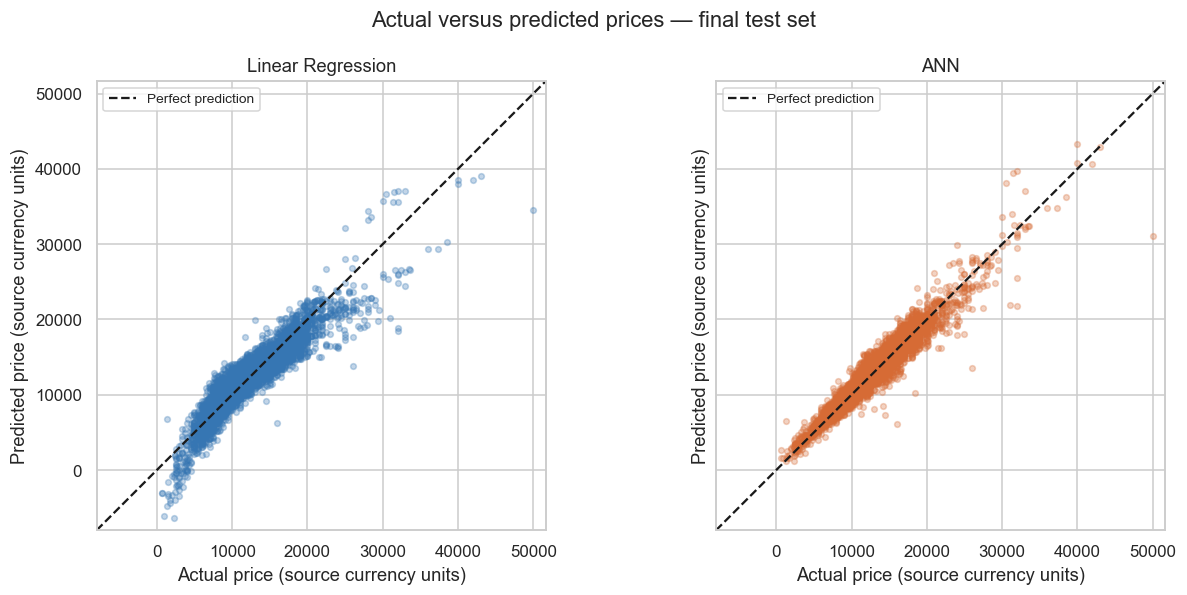

In [30]:
all_primary_values = np.concatenate([y_test.to_numpy(), *[test_predictions[name] for name in primary_models]])
low, high = float(all_primary_values.min()), float(all_primary_values.max())
padding = max((high - low) * 0.03, 1.0)
limits = (low - padding, high + padding)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
for ax, name in zip(axes, primary_models):
    ax.scatter(y_test, test_predictions[name], alpha=0.3, s=14, color=COLORS[name])
    ax.plot(limits, limits, "k--", label="Perfect prediction")
    ax.set(title=name, xlabel="Actual price (source currency units)",
           ylabel="Predicted price (source currency units)", xlim=limits, ylim=limits)
    ax.set_aspect("equal", adjustable="box")
    ax.legend(fontsize=9)
fig.suptitle("Actual versus predicted prices — final test set")
fig.tight_layout()
plt.show()


**Read the result**

Look for systematic deviations at low and high prices rather than judging only the densest cluster. Negative predictions remain visible on the shared scale.


### 30. Compare residual patterns

- Residual-versus-prediction plots reveal curvature and changing error spread.
- Histograms show the distribution of positive and negative errors; use common bin edges for comparison.
- Q–Q plots compare residual quantiles with a normal distribution. Normality is not required to calculate predictions, MAE, RMSE, or R².
- The test residuals need not sum to zero. ANN training residuals also have no general zero-sum guarantee.


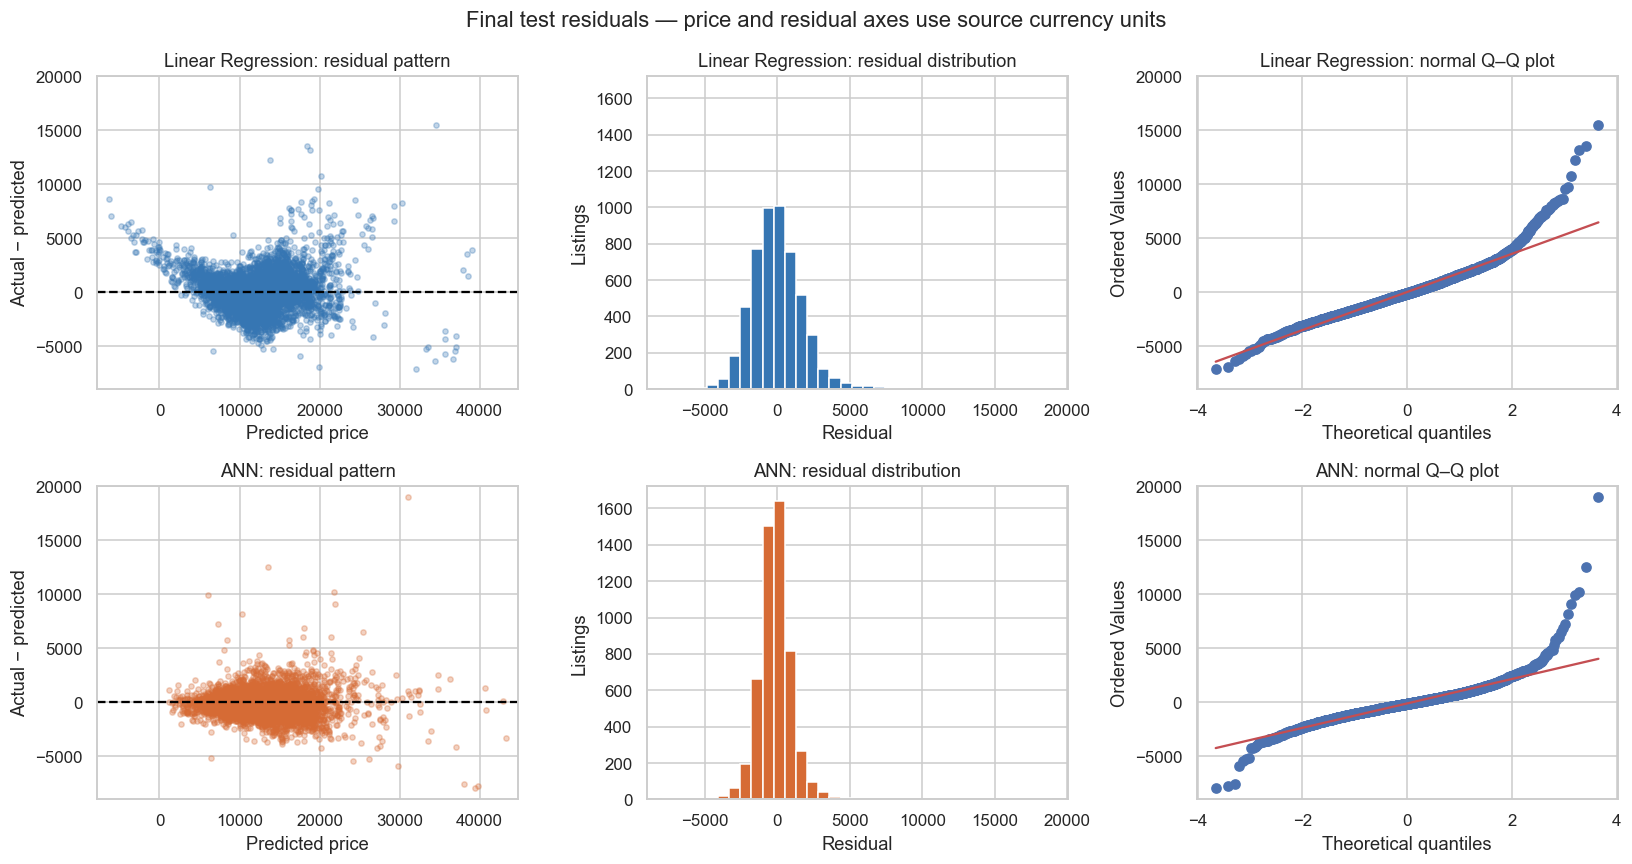

In [31]:
residuals = {name: y_test.to_numpy() - test_predictions[name] for name in primary_models}
pooled_residuals = np.concatenate(list(residuals.values()))
residual_low, residual_high = float(pooled_residuals.min()), float(pooled_residuals.max())
residual_padding = max((residual_high - residual_low) * 0.04, 1.0)
residual_limits = (residual_low - residual_padding, residual_high + residual_padding)
histogram_edges = np.histogram_bin_edges(pooled_residuals, bins=35)
prediction_low = min(float(test_predictions[name].min()) for name in primary_models)
prediction_high = max(float(test_predictions[name].max()) for name in primary_models)
prediction_padding = max((prediction_high - prediction_low) * 0.03, 1.0)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for row, name in enumerate(primary_models):
    axes[row, 0].scatter(test_predictions[name], residuals[name], alpha=0.3,
                         s=12, color=COLORS[name])
    axes[row, 0].axhline(0, color="black", linestyle="--")
    axes[row, 0].set(title=f"{name}: residual pattern", xlabel="Predicted price",
                     ylabel="Actual − predicted", ylim=residual_limits,
                     xlim=(prediction_low - prediction_padding, prediction_high + prediction_padding))
    axes[row, 1].hist(residuals[name], bins=histogram_edges, color=COLORS[name], edgecolor="white")
    axes[row, 1].set(title=f"{name}: residual distribution", xlabel="Residual", ylabel="Listings",
                     xlim=residual_limits)
    stats.probplot(residuals[name], dist="norm", plot=axes[row, 2])
    axes[row, 2].set_title(f"{name}: normal Q–Q plot")
    axes[row, 2].set_ylim(residual_limits)
max_histogram_height = max(ax.get_ylim()[1] for ax in axes[:, 1])
for ax in axes[:, 1]:
    ax.set_ylim(0, max_histogram_height)
fig.suptitle("Final test residuals — price and residual axes use source currency units")
fig.tight_layout()
plt.show()


**Read the result**

A widening residual band suggests larger errors for more expensive cars. Heavy Q–Q tails can indicate unusually large errors. A clean-looking plot alone does not establish calibrated uncertainty or causal explanations.


### 31. Add a paired bootstrap interval for the error difference

- This optional extension resamples the **same test-row indices** for both fixed models, preserving the pairing of their errors.
- Estimate ANN minus LR for MAE and RMSE; negative differences favor ANN.
- Use percentile intervals from the resampled differences. An interval crossing zero indicates that the direction is uncertain under this resampling procedure.
- These approximate 95% intervals describe test-sample variation conditional on the fitted models. They do not include retraining, initialization, hyperparameter-search, or market-shift uncertainty.
- Row resampling assumes listings are independent. Repeated listings of one car would require vehicle-level grouped resampling when identifiers are available.


In [32]:
bootstrap_summary = pd.DataFrame()
if RUN_BOOTSTRAP:
    if BOOTSTRAP_REPEATS < 100:
        raise ValueError("Use at least 100 bootstrap repeats; 2000 is the lesson default.")
    rng = np.random.default_rng(RANDOM_STATE)
    actual = y_test.to_numpy()
    lr_errors = actual - test_predictions["Linear Regression"]
    ann_errors = actual - test_predictions["ANN"]
    differences = np.empty((BOOTSTRAP_REPEATS, 2))
    for repeat in range(BOOTSTRAP_REPEATS):
        positions = rng.integers(0, len(actual), size=len(actual))
        lr_sample = lr_errors[positions]
        ann_sample = ann_errors[positions]
        differences[repeat, 0] = np.mean(np.abs(ann_sample)) - np.mean(np.abs(lr_sample))
        differences[repeat, 1] = np.sqrt(np.mean(ann_sample ** 2)) - np.sqrt(np.mean(lr_sample ** 2))
    rows = []
    for column, metric in enumerate(["MAE", "RMSE"]):
        lower, upper = np.quantile(differences[:, column], [0.025, 0.975])
        rows.append({"Metric": metric,
                     "ANN minus LR": test_metrics.loc["ANN", metric] - test_metrics.loc["Linear Regression", metric],
                     "95% lower": lower, "95% upper": upper})
    bootstrap_summary = pd.DataFrame(rows).set_index("Metric")
    display(bootstrap_summary.round(2))
    print("Differences and intervals are in source currency units; negative favors ANN.")
else:
    print("Bootstrap extension disabled in configuration.")


,ANN minus LR,95% lower,95% upper
Metric,,,
MAE,-507.51,-536.29,-476.44
RMSE,-610.32,-666.23,-553.80


Differences and intervals are in source currency units; negative favors ANN.


**Read the result**

An interval wholly below zero supports lower ANN error under these assumptions for the fixed fitted models. It is not a guarantee that ANN will win after retraining or on another market. These intervals are for metric differences, not individual car prices.


### 32. Predict the same new-car example with every model

- Preserve the source example: a 2020 automatic petrol Fiesta with mileage 1,000, tax 150, mpg 57.7, and engine size 1.5.
- Pass named raw features through each model's fitted preprocessing; ANN also restores the target's original scale.
- Flag unseen categories and numeric values outside observed training ranges.
- Range checks cannot establish that a combination of otherwise familiar values was represented during training.


In [33]:
new_car = pd.DataFrame([{
    "model": "Fiesta", "year": 2020, "transmission": "Automatic",
    "mileage": 1000, "fuelType": "Petrol", "tax": 150,
    "mpg": 57.7, "engineSize": 1.5
}])[feature_columns]

input_warnings = []
for column in categorical_features:
    if new_car.at[0, column] not in set(X_train[column].dropna()):
        input_warnings.append(f"Unseen {column}: {new_car.at[0, column]}")
for column in numeric_features:
    observed = X_train[column].dropna()
    value = new_car.at[0, column]
    if not observed.min() <= value <= observed.max():
        input_warnings.append(f"{column}={value} is outside the observed training range.")

new_predictions = pd.DataFrame({
    "Predicted advertised price": {name: float(predict_model(name, new_car)[0]) for name in model_order}
})
display(new_car)
display(new_predictions.round(2))
for message in input_warnings:
    print("Caution:", message)
for name in model_order:
    if new_predictions.loc[name, "Predicted advertised price"] < 0:
        print(f"Caution: {name} produced a negative price.")


,year,mileage,tax,mpg,engineSize,model,transmission,fuelType
0,2020,1000,150,57.7,1.5,Fiesta,Automatic,Petrol


,Predicted advertised price
Linear Regression,16953.93
ANN,14957.24
Log-target Linear Regression,18515.99
Median baseline,11298.00


**Read the result**

These are point estimates of advertised price, not guaranteed transaction prices or prediction intervals. Model disagreement is a reason to examine the example and its support in the training data.


### 33. Optionally export the experiment tables

- Set `SAVE_RESULTS=True` to save CSV tables to `OUTPUT_DIR` on your own computer.
- Export the metrics, CV results, predictions, ANN learning history, timing, and configuration together so the experiment can be explained later.
- All files are calculated from the CSV you supplied; no historical source-notebook scores are mixed into the new results.


In [34]:
if SAVE_RESULTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    test_metrics.to_csv(OUTPUT_DIR / "test_metrics.csv")
    train_metrics.to_csv(OUTPUT_DIR / "training_metrics.csv")
    primary_comparison.to_csv(OUTPUT_DIR / "ann_vs_lr_comparison.csv")
    cv_results.to_csv(OUTPUT_DIR / "cv_fold_metrics.csv", index=False)
    cv_summary.to_csv(OUTPUT_DIR / "cv_summary.csv")
    cv_ann_details.to_csv(OUTPUT_DIR / "ann_cv_training_details.csv", index=False)
    test_results.to_csv(OUTPUT_DIR / "test_predictions.csv", index=True)
    ann_history.to_csv(OUTPUT_DIR / "ann_epoch_selection_history.csv", index=False)
    cost_and_validity.to_csv(OUTPUT_DIR / "timing_and_negative_predictions.csv")
    new_predictions.to_csv(OUTPUT_DIR / "new_car_predictions.csv")
    if not bootstrap_summary.empty:
        bootstrap_summary.to_csv(OUTPUT_DIR / "paired_bootstrap_differences.csv")
    configuration = {
        "data_path": str(data_path.resolve()), "random_state": RANDOM_STATE,
        "test_fraction": TEST_SIZE, "cv_folds": CV_FOLDS,
        "hidden_layers": str(ANN_HIDDEN_LAYERS), "learning_rate": ANN_LEARNING_RATE,
        "l2_alpha": ANN_ALPHA, "batch_size": ANN_BATCH_SIZE,
        "max_epochs": ANN_MAX_EPOCHS, "patience": ANN_PATIENCE,
        "min_delta_scaled_rmse": ANN_MIN_DELTA, "inner_validation_fraction": ANN_VALIDATION_SIZE,
        "selected_final_epochs": ann_info["selected_epochs"],
        "cv_preferred_primary_model": preferred_by_cv,
        "min_model_year": MIN_MODEL_YEAR, "max_model_year": MAX_MODEL_YEAR,
        "zero_engine_size_is_missing": ZERO_ENGINE_SIZE_IS_MISSING,
        "include_log_lr": RUN_LOG_LR_REFERENCE, "bootstrap_enabled": RUN_BOOTSTRAP,
        "bootstrap_repeats": BOOTSTRAP_REPEATS,
        "python_version": platform.python_version(), "sklearn_version": sklearn.__version__,
        "numpy_version": np.__version__, "pandas_version": pd.__version__
    }
    pd.Series(configuration, name="Value").to_csv(OUTPUT_DIR / "experiment_configuration.csv")
    print(f"Saved experiment tables to {OUTPUT_DIR.resolve()}")
else:
    print("Export disabled. Set SAVE_RESULTS=True if you want CSV result files.")


Export disabled. Set SAVE_RESULTS=True if you want CSV result files.


**Read the result**

The exported per-row predictions allow the metrics to be independently recomputed. Keep the exact source CSV and software environment if you need to reproduce the fitted experiment.


## Interpretation and limits

- **What is learned?** Advertised prices of Ford listings resembling the training sample. This is not a direct model of realized sale prices or other manufacturers.
- **What makes the comparison fair?** The same cleaned records, eight predictors, holdout rows, preprocessing specification, CV fold indices, metric definitions, and original-currency evaluation. ANN epoch selection is isolated within each training pool, and its final refit uses the full pool.
- **Does target standardization give ANN different information?** No. It is an invertible affine transformation fitted on training targets, and predictions are mapped back before evaluation. It changes optimization conditioning, not the target information. The optional log-target reference is different: its nonlinear transformation changes the fitting objective.
- **Why is ANN not guaranteed to win?** The data may be close to additive, the sample may be small, the chosen network may underfit or overfit, or important predictors may be missing.
- **How broad is the evidence?** One random holdout and one shuffled five-fold CV run. ANN randomness, other splits, alternative hyperparameters, and future markets can change the result.
- **What does the random split omit?** Future-market shifts and repeated listings of the same physical car. Use chronological or vehicle-group splits when appropriate identifiers become available.
- **What about duplicate removal?** Exact duplicates are removed before splitting, as in the source. Identical specifications can sometimes represent different real cars; review this policy when listing or vehicle identifiers are available.
- **What about data corrections?** Implausible years and invalid measurements are marked missing, not replaced with invented true values. Authoritative source corrections are preferable.
- **What about rare or unfamiliar inputs?** One-hot encoding can run without a matching category, but prediction reliability is not established by successful execution. Individually familiar values can form an unfamiliar combination.
- **What follows from the test diagnostics?** They describe the final specified models. Once they guide a model change, the same test set becomes development data; use fresh evaluation data for the revised model.
- **What uncertainty is provided?** Optional paired intervals for MAE/RMSE differences only. No individual prediction intervals or causal claims are supplied.

## Classroom questions and extensions

1. Explain why categorical labels are one-hot encoded instead of assigning arbitrary integers.
2. Why can eight raw predictors become more than eight ANN inputs? Verify the parameter-count formula for the first hidden layer.
3. Explain the difference between a batch, an epoch, and an early-stopping patience value.
4. Why are fitting and validation rows split before fitting the input and target scalers?
5. Why is the final network refitted after selecting its epoch count? Why can its weights differ from those of the inner network?
6. If ANN has lower MAE but higher RMSE, what does that suggest about its error distribution?
7. Explain why a near-zero mean residual does not imply accurate predictions, and why R² is not an accuracy percentage.
8. Before a new test evaluation, compare hidden layers `(32,)`, `(64, 32)`, and `(128, 64)` using training-only model selection. Include the computational cost.
9. Study regularization and random seeds using only development data. For an unbiased assessment of a selected configuration, place the entire selection inside outer CV or reserve a fresh test set.
10. Consider a future-market evaluation with chronological splits, and a vehicle-level split if repeated listings can be identified.

## Official implementation references

- [MLPRegressor API and incremental training](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html)
- [Supervised neural networks and feature scaling](https://scikit-learn.org/stable/modules/neural_networks_supervised.html)
- [Preprocessing leakage and pipelines](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)
- [TransformedTargetRegressor for the optional log-target reference](https://scikit-learn.org/stable/modules/generated/sklearn.compose.TransformedTargetRegressor.html)
- [Regression metrics and their interpretation](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics)
- [Mean absolute percentage error](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_percentage_error.html)

**Source adaptation:** the supplied `AI07_LR_Used_Car_Price_Prediction(1).ipynb` provides the task, author block, feature schema, deterministic cleaning rules, split settings, exploration, and example car. This companion adds ANN teaching, isolated epoch selection and refitting, shared-fold comparisons, additional metrics, and current result-driven interpretation. Its historical output values are not reused as results.
